In [24]:
# ==========================================
# Day 7: Trace & Event Sequence Mining
# ==========================================

In [25]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")


In [26]:
# 1. Load Processed Event Log Data (Using correct filename)
df_events = pd.read_csv('../data/processed_new/careflow_events_scaled.csv')

# Ensure timestamp parsing
df_events['timestamp'] = pd.to_datetime(df_events['timestamp'])
df_events = df_events.sort_values(by=['case_id', 'timestamp'])

print(f"Total Event Records Loaded: {len(df_events)}")
print(f"Total Unique Cases: {df_events['case_id'].nunique()}")
print(df_events.head(3))


Total Event Records Loaded: 6964
Total Unique Cases: 1000
   case_id      activity_name activity_category           timestamp  \
0  CF00001       Registration    Administrative 2026-01-06 15:31:00   
1  CF00001             Triage    Administrative 2026-01-06 15:53:00   
2  CF00001  Doctor Assessment          Clinical 2026-01-06 16:13:00   

   activity_order  activity_occurrence  is_repeat_activity  \
0               1                    1               False   
1               2                    1               False   
2               3                    1               False   

   minutes_since_prev  minutes_since_case_start resource  ...  day_of_week  \
0                 0.0                       0.0     DR06  ...      Tuesday   
1                22.0                      22.0     DR06  ...      Tuesday   
2                20.0                      42.0     DR06  ...      Tuesday   

   split  minutes_since_prev_z minutes_since_case_start_z     age_z  acuity_z  \
0  train      

In [27]:
# 2. Extract Patient Traces (Event Sequences)
# Grouping by case_id to create an ordered list of activities per case
trace_df = df_events.groupby('case_id')['activity_name'].apply(lambda x: ' -> '.join(x)).reset_index()
trace_df.columns = ['case_id', 'trace_sequence']

# Calculate Trace Length (number of events in a case)
trace_df['trace_length'] = trace_df['trace_sequence'].apply(lambda x: len(x.split(' -> ')))

print("\n--- Sample Traces ---")
display(trace_df.head())


--- Sample Traces ---


,case_id,trace_sequence,trace_length
0,CF00001,Registration -> Triage -> Doctor Assessment ->...,4
1,CF00002,Registration -> Triage -> Doctor Assessment ->...,4
2,CF00003,Registration -> Triage -> Doctor Assessment ->...,4
3,CF00004,Registration -> Triage -> Doctor Assessment ->...,9
4,CF00005,Registration -> Triage -> Doctor Assessment ->...,11


In [28]:
# 3. Analyze Trace Variants (Frequency)
variant_counts = trace_df['trace_sequence'].value_counts().reset_index()
variant_counts.columns = ['trace_sequence', 'frequency']
variant_counts['percentage'] = (variant_counts['frequency'] / len(trace_df)) * 100

print("\n--- Top 5 Most Common Patient Pathways ---")
display(variant_counts.head())


--- Top 5 Most Common Patient Pathways ---


,trace_sequence,frequency,percentage
0,Registration -> Triage -> Doctor Assessment ->...,267,26.7
1,Registration -> Triage -> Doctor Assessment ->...,216,21.6
2,Registration -> Triage -> Doctor Assessment ->...,149,14.9
3,Registration -> Triage -> Doctor Assessment ->...,146,14.6
4,Registration -> Triage -> Doctor Assessment ->...,133,13.3


C:\Users\HP\AppData\Local\Temp\ipykernel_3336\1089270013.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\HP\AppData\Local\Temp\ipykernel_3336\1089270013.py:12: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


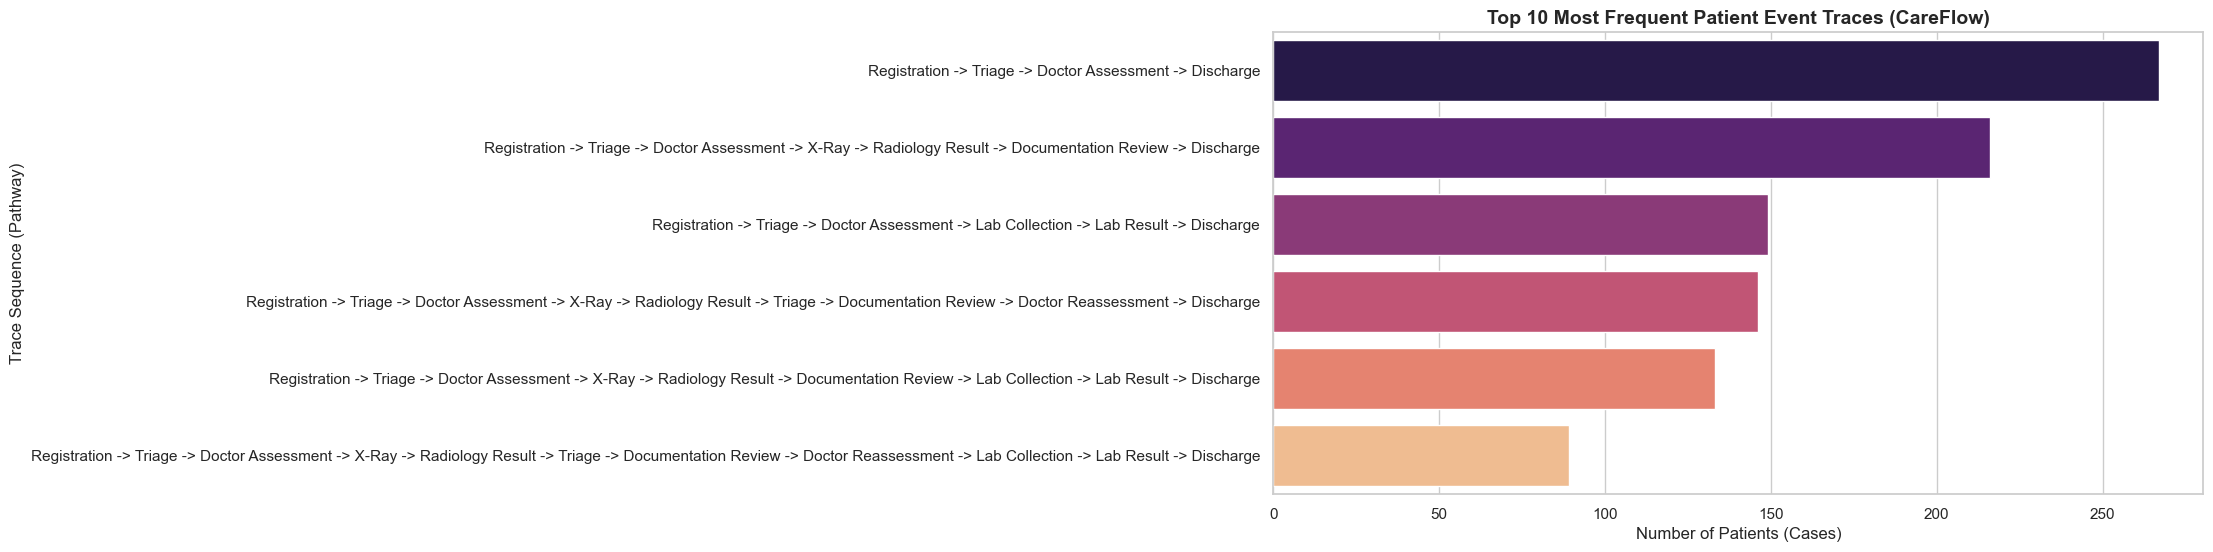

In [29]:
# 4. Visualization: Top 10 Trace Variants
plt.figure(figsize=(12, 6))
sns.barplot(
    data=variant_counts.head(10),
    y='trace_sequence',
    x='frequency',
    palette='magma'
)
plt.title('Top 10 Most Frequent Patient Event Traces (CareFlow)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Patients (Cases)', fontsize=12)
plt.ylabel('Trace Sequence (Pathway)', fontsize=12)
plt.tight_layout()
plt.show()

In [30]:
# 5. Loopback / Re-entry Detection (Bottleneck Identifier)
def detect_loopbacks(trace_str):
    activities = trace_str.split(' -> ')
    return len(activities) != len(set(activities))

trace_df['has_loopback'] = trace_df['trace_sequence'].apply(detect_loopbacks)
loopback_rate = (trace_df['has_loopback'].sum() / len(trace_df)) * 100

print(f"\n--- Loopback Analysis ---")
print(f"Cases with Repeated Activities (Loopbacks): {trace_df['has_loopback'].sum()} ({loopback_rate:.2f}%)")


--- Loopback Analysis ---
Cases with Repeated Activities (Loopbacks): 235 (23.50%)


### 📌 Day 7 Key Insights & PM Summary

1. **Trace Diversity:** Identified distinct patient journey variants across all cases. A few dominant traces represent the standard clinical pathway.
2. **Loopbacks & Re-work:** Detected cases with repeated activity steps (e.g., Triage re-entry or repeated assessments), highlighting operational rework and friction points.
3. **Process Mining Readiness:** These aggregated trace sequences feed directly into PM4Py process map visualizations and Power BI process mining visuals.